In [1]:
# The setup cell

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA

DATA_PATH = "Dataset/Dataset.csv"
SAMPLE_START = "2011-01-01"
SAMPLE_END   = "2018-12-31"

df = pd.read_csv(DATA_PATH)
df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
df = df.sort_values("time").reset_index(drop=True)

# I use the same exact timeframe as Liu and Tsyvinski
df = df.loc[
    (df["time"] >= pd.Timestamp(SAMPLE_START, tz="UTC")) &
    (df["time"] <= pd.Timestamp(SAMPLE_END,   tz="UTC"))
].copy()


if "btc_return" in df.columns and "bitcoin_return" in df.columns:
    df["bitcoin_full_return"] = df["btc_return"].combine_first(df["bitcoin_return"])
elif "btc_return" in df.columns:
    df["bitcoin_full_return"] = df["btc_return"]
elif "bitcoin_return" in df.columns:
    df["bitcoin_full_return"] = df["bitcoin_return"]
else:
    raise ValueError("Neither 'btc_return' nor 'bitcoin_return' exists in the dataset.")

# The helper fımctions for later
def compound_return(x: pd.Series) -> float:
    x = pd.Series(x).dropna()
    if len(x) == 0:
        return np.nan
    return np.prod(1.0 + x.values) - 1.0

def build_frequency_panel(data: pd.DataFrame, freq: str) -> pd.DataFrame:
    """
    Builds daily, weekly, monthly panel.

    freq:
    - 'D'      = daily
    - 'W-SUN'  = weekly
    - 'M'      = monthly
    """
    data = data.copy().set_index("time")

    ret_cols = [
        "CMKT",
        "bitcoin_full_return",
        "ethereum_return",
        "ripple_return",
        "stock_market_return",
    ]
    level_cols_last = [
        "active_addresses",
        "transaction_count",
        "payment_transfer_count",
        "total_market_cap",
    ]

    agg_map = {c: compound_return for c in ret_cols if c in data.columns}
    agg_map.update({c: "last" for c in level_cols_last if c in data.columns})

    out = data.resample(freq).agg(agg_map).reset_index()

    out = out.dropna(subset=["CMKT"]).copy()

    return out.reset_index(drop=True)

def summary_stats(s: pd.Series) -> dict:
    s = pd.Series(s).dropna()
    n = len(s)
    mean = s.mean()
    sd = s.std(ddof=1)
    t_stat = mean / (sd / np.sqrt(n)) if n > 1 and sd > 0 else np.nan
    sharpe = mean / sd if sd > 0 else np.nan

    return {
        "Mean": mean,
        "SD": sd,
        "t-Stat": t_stat,
        "Sharpe": sharpe,
        "Skewness": s.skew(),
        "Kurtosis": s.kurtosis() + 3.0,
        "% > 0": 100.0 * (s > 0).mean(),
        "N": n,
    }

def format_pct(x):
    return f"{100*x:.2f}%"

def format_num(x):
    return f"{x:.2f}"

def cumulative_future_return(r: pd.Series, h: int) -> pd.Series:
    """
    Future cumulative return from t+1 to t+h
    """
    r = pd.Series(r).reset_index(drop=True)
    out = pd.Series(np.nan, index=r.index, dtype="float64")

    vals = r.to_numpy()
    for i in range(len(vals)):
        future = vals[i+1:i+1+h]
        if len(future) == h and np.isfinite(future).all():
            out.iloc[i] = np.prod(1.0 + future) - 1.0

    return out

def hac_mean_tstat(series: pd.Series, lags: int):
    y = pd.Series(series).dropna().astype(float)
    if len(y) == 0:
        return np.nan, np.nan

    X = np.ones((len(y), 1))
    fit = sm.OLS(y.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(fit.params[0]), float(fit.tvalues[0])

def run_predictive_regression(y: pd.Series, x: pd.Series, lags: int):
    tmp = pd.DataFrame({"y": y, "x": x}).dropna().copy()
    X = sm.add_constant(tmp["x"])
    fit = sm.OLS(tmp["y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

    return {
        "N": int(fit.nobs),
        "coef": float(fit.params["x"]),
        "tstat": float(fit.tvalues["x"]),
        "R2": float(fit.rsquared),
    }

def significance_stars(t):
    at = abs(t)
    if at >= 2.58:
        return "***"
    elif at >= 1.96:
        return "**"
    elif at >= 1.645:
        return "*"
    return ""

def cointegration_residual_ratio(fundamental: pd.Series, market_cap: pd.Series) -> pd.Series:
    tmp = pd.DataFrame({"fundamental": fundamental, "mcap": market_cap}).dropna().copy()
    tmp = tmp.loc[(tmp["fundamental"] > 0) & (tmp["mcap"] > 0)].copy()

    out = pd.Series(np.nan, index=fundamental.index, dtype="float64")
    if len(tmp) < 20:
        return out

    X = sm.add_constant(np.log(tmp["mcap"]))
    y = np.log(tmp["fundamental"])
    fit = sm.OLS(y, X).fit()

    out.loc[tmp.index] = fit.resid
    return out

print("Loaded rows:", len(df))
print("Date range :", df["time"].min(), "to", df["time"].max())
print("Columns    :", list(df.columns))
print("Bitcoin full-sample non-missing obs:", df["bitcoin_full_return"].notna().sum())

Loaded rows: 2922
Date range : 2011-01-01 00:00:00+00:00 to 2018-12-31 00:00:00+00:00
Columns    : ['time', 'active_addresses', 'transaction_count', 'payment_transfer_count', 'stock_market_return', 'RF', 'RF_decimal', 'bitcoin_search', 'bitcoin_hack_search', 'ethereum_search', 'ripple_search', 'litecoin_search', 'tether_search', 'bitcoin_cash_search', 'tezos_search', 'binance_coin_search', 'monero_search', 'cardano_search', 'CMKT', 'total_market_cap', 'total_volume_24h', 'n_coins', 'CMKT_original', 'btc_price_usd', 'btc_return', 'CMKT_source', 'bitcoin_price_usd', 'ethereum_price_usd', 'ripple_price_usd', 'bitcoin_return', 'ethereum_return', 'ripple_return', 'bitcoin_full_return']
Bitcoin full-sample non-missing obs: 2921


In [2]:
# The daily, weekly, monthly panels

daily   = build_frequency_panel(df, "D")
weekly  = build_frequency_panel(df, "W-SUN")
monthly = build_frequency_panel(df, "M")

print("Daily rows  :", len(daily),   daily["time"].min(),   "to", daily["time"].max())
print("Weekly rows :", len(weekly),  weekly["time"].min(),  "to", weekly["time"].max())
print("Monthly rows:", len(monthly), monthly["time"].min(), "to", monthly["time"].max())

print("\nNon-missing observations by frequency:")
print("Daily Bitcoin  :", daily["bitcoin_full_return"].notna().sum())
print("Weekly Bitcoin :", weekly["bitcoin_full_return"].notna().sum())
print("Monthly Bitcoin:", monthly["bitcoin_full_return"].notna().sum())

Daily rows  : 2921 2011-01-02 00:00:00+00:00 to 2018-12-31 00:00:00+00:00
Weekly rows : 419 2011-01-02 00:00:00+00:00 to 2019-01-06 00:00:00+00:00
Monthly rows: 96 2011-01-31 00:00:00+00:00 to 2018-12-31 00:00:00+00:00

Non-missing observations by frequency:
Daily Bitcoin  : 2921
Weekly Bitcoin : 419
Monthly Bitcoin: 96


In [3]:
# Table 1: Summary Statistics

def build_table1_panel(panel: pd.DataFrame, label: str) -> pd.DataFrame:
    series_map = {
        "CMKT": "CMKT",
        "Bitcoin": "bitcoin_full_return",  
        "Ethereum": "ethereum_return",
        "Ripple": "ripple_return",
        "Stock": "stock_market_return",
    }

    rows = []
    for name, col in series_map.items():
        if col not in panel.columns:
            continue
        s = panel[col].dropna()
        if len(s) == 0:
            continue

        stats_dict = summary_stats(s)
        rows.append({
            "Frequency": label,
            "Asset": name,
            "Mean": format_pct(stats_dict["Mean"]),
            "SD": format_pct(stats_dict["SD"]),
            "t-Stat": format_num(stats_dict["t-Stat"]),
            "Sharpe": format_num(stats_dict["Sharpe"]),
            "Skewness": format_num(stats_dict["Skewness"]),
            "Kurtosis": format_num(stats_dict["Kurtosis"]),
            "% > 0": format_num(stats_dict["% > 0"]),
            "N": stats_dict["N"],
        })

    return pd.DataFrame(rows)

table1_daily   = build_table1_panel(daily,   "Daily")
table1_weekly  = build_table1_panel(weekly,  "Weekly")
table1_monthly = build_table1_panel(monthly, "Monthly")

table1_panel_a = pd.concat([table1_daily, table1_weekly, table1_monthly], axis=0).reset_index(drop=True)

thresholds = [0.05, 0.10, 0.20, 0.30]
cmkt_daily = daily["CMKT"].dropna()

extreme_rows = []
for thr in thresholds:
    extreme_rows.append({
        "Disasters": f"< -{int(100*thr)}%",
        "Counts": int((cmkt_daily < -thr).sum()),
        "%": f"{100*(cmkt_daily < -thr).mean():.2f}%",
        "Miracles": f"> {int(100*thr)}%",
        "Counts ": int((cmkt_daily > thr).sum()),
        "% ": f"{100*(cmkt_daily > thr).mean():.2f}%",
    })

table1_panel_b = pd.DataFrame(extreme_rows)

print("\nTABLE 1 — PANEL A")
display(table1_panel_a)

print("\nTABLE 1 — PANEL B")
display(table1_panel_b)


TABLE 1 — PANEL A


,Frequency,Asset,Mean,SD,t-Stat,Sharpe,Skewness,Kurtosis,% > 0,N
0,Daily,CMKT,0.48%,5.57%,4.63,0.09,0.83,15.64,50.87,2921
1,Daily,Bitcoin,0.48%,5.56%,4.62,0.09,0.90,15.62,50.43,2921
2,Daily,Ethereum,0.60%,7.38%,2.86,0.08,0.27,16.05,48.87,1242
3,Daily,Ripple,0.53%,8.86%,2.66,0.06,6.07,100.56,46.08,1975
4,Daily,Stock,0.04%,0.92%,1.85,0.04,-0.45,7.95,53.95,2011
5,Weekly,CMKT,3.47%,16.53%,4.29,0.21,1.71,9.95,56.09,419
6,Weekly,Bitcoin,3.43%,16.30%,4.31,0.21,1.77,10.38,57.52,419
7,Weekly,Ethereum,4.78%,24.24%,2.64,0.20,1.47,7.76,51.40,179
8,Weekly,Ripple,5.68%,45.51%,2.10,0.12,7.82,82.32,46.29,283
9,Weekly,Stock,0.18%,1.91%,1.93,0.09,-0.47,5.16,58.61,418



TABLE 1 — PANEL B


,Disasters,Counts,%,Miracles,Counts,%
0,< -5%,255,8.73%,> 5%,316,10.82%
1,< -10%,83,2.84%,> 10%,121,4.14%
2,< -20%,16,0.55%,> 20%,26,0.89%
3,< -30%,3,0.10%,> 30%,11,0.38%


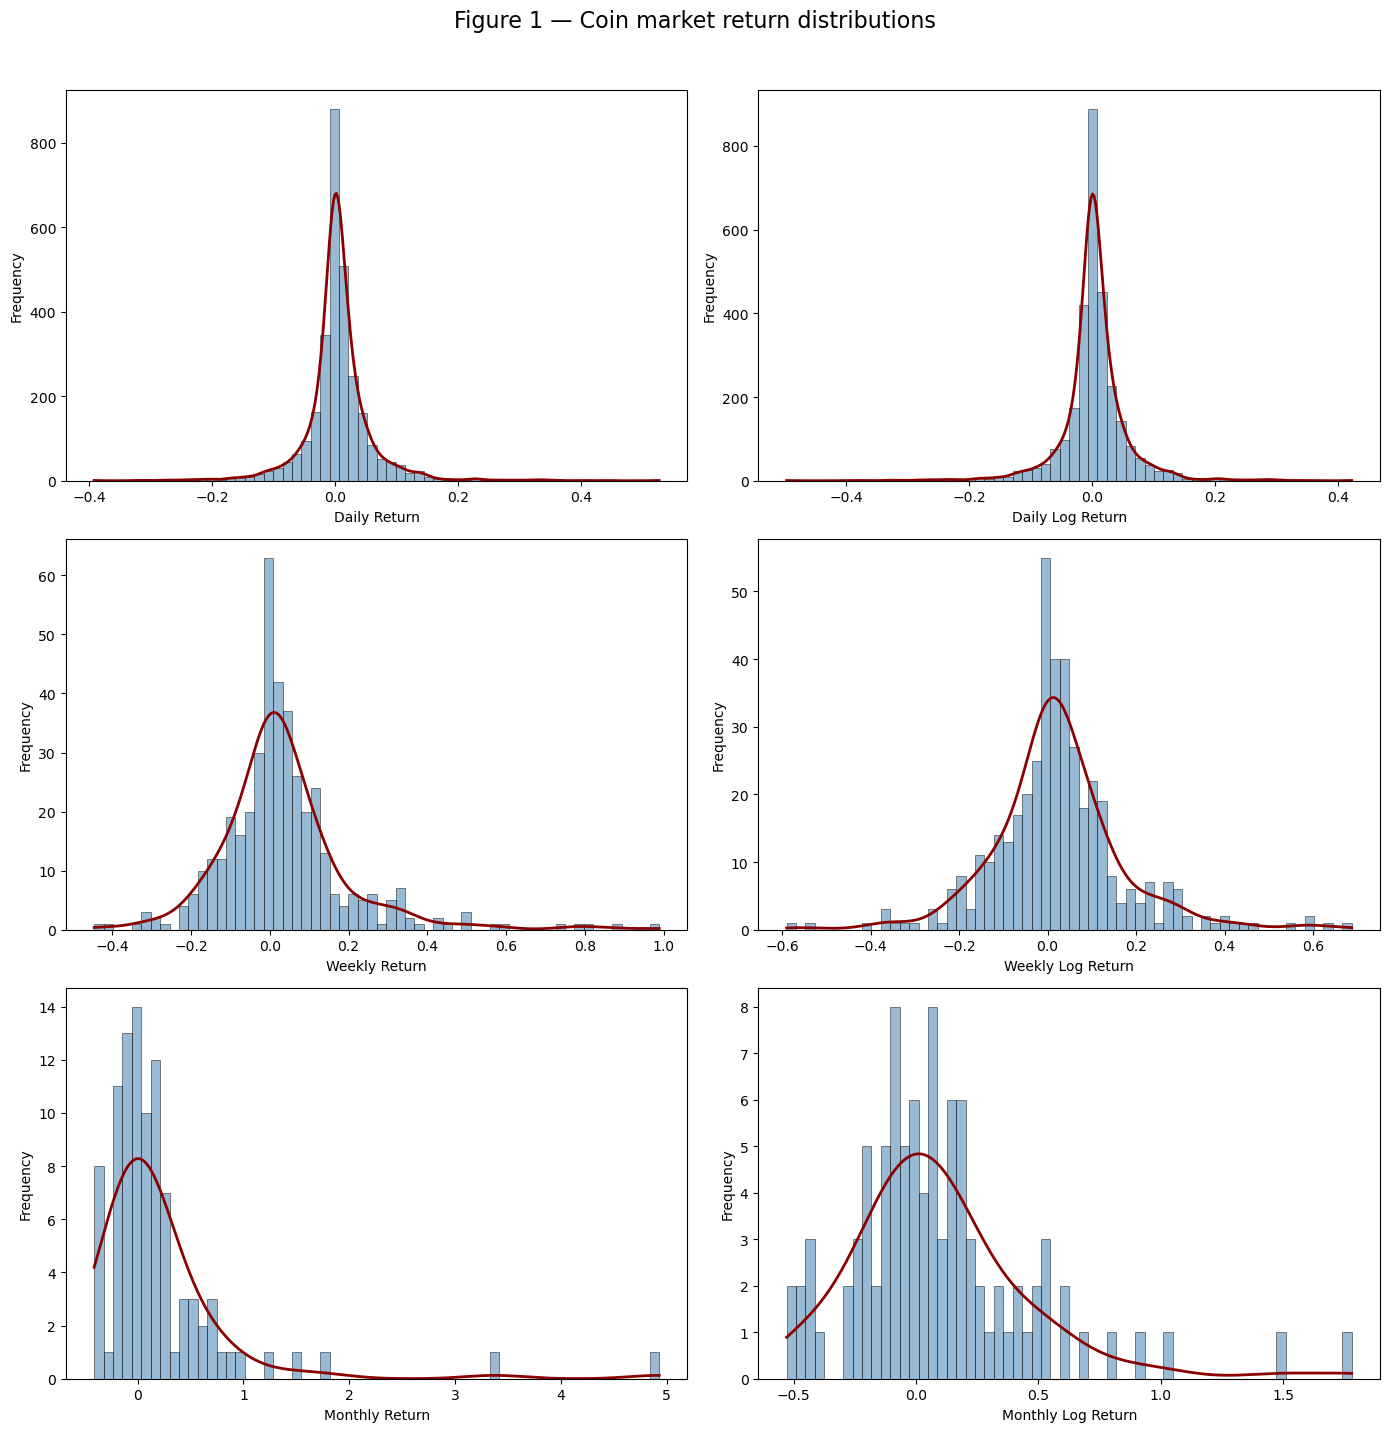

In [4]:
# Figure 1: Coin Market Return Distributions

# Note: I was unsure whether it would be more appropriate for me to change the colors of the visualizations or not
# Decided to stay true to the original until the final draft
fig, axes = plt.subplots(3, 2, figsize=(14, 14))

freq_map = {
    "Daily": daily["CMKT"].dropna(),
    "Weekly": weekly["CMKT"].dropna(),
    "Monthly": monthly["CMKT"].dropna(),
}

hist_color = "steelblue"
line_color = "darkred"
edge_color = "black"

for row_idx, (label, s) in enumerate(freq_map.items()):

    ax = axes[row_idx, 0]
    vals = s.dropna().values

    ax.hist(
        vals,
        bins=60,
        density=False,
        color=hist_color,
        edgecolor=edge_color,
        linewidth=0.6,
        alpha=0.55
    )

    if len(vals) > 5 and np.std(vals) > 0:
        kde = gaussian_kde(vals)
        grid = np.linspace(np.min(vals), np.max(vals), 400)

        bin_width = (np.max(vals) - np.min(vals)) / 60
        kde_scaled = kde(grid) * len(vals) * bin_width

        ax.plot(grid, kde_scaled, color=line_color, linewidth=2)

    ax.set_xlabel(f"{label} Return")
    ax.set_ylabel("Frequency")
    ax.set_title("")

    ax = axes[row_idx, 1]
    log_vals = np.log1p(s[s > -1]).dropna().values

    ax.hist(
        log_vals,
        bins=60,
        density=False,
        color=hist_color,
        edgecolor=edge_color,
        linewidth=0.6,
        alpha=0.55
    )

    if len(log_vals) > 5 and np.std(log_vals) > 0:
        kde = gaussian_kde(log_vals)
        grid = np.linspace(np.min(log_vals), np.max(log_vals), 400)

        bin_width = (np.max(log_vals) - np.min(log_vals)) / 60
        kde_scaled = kde(grid) * len(log_vals) * bin_width

        ax.plot(grid, kde_scaled, color=line_color, linewidth=2)

    ax.set_xlabel(f"{label} Log Return")
    ax.set_ylabel("Frequency")
    ax.set_title("")

plt.suptitle("Figure 1 — Coin market return distributions", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

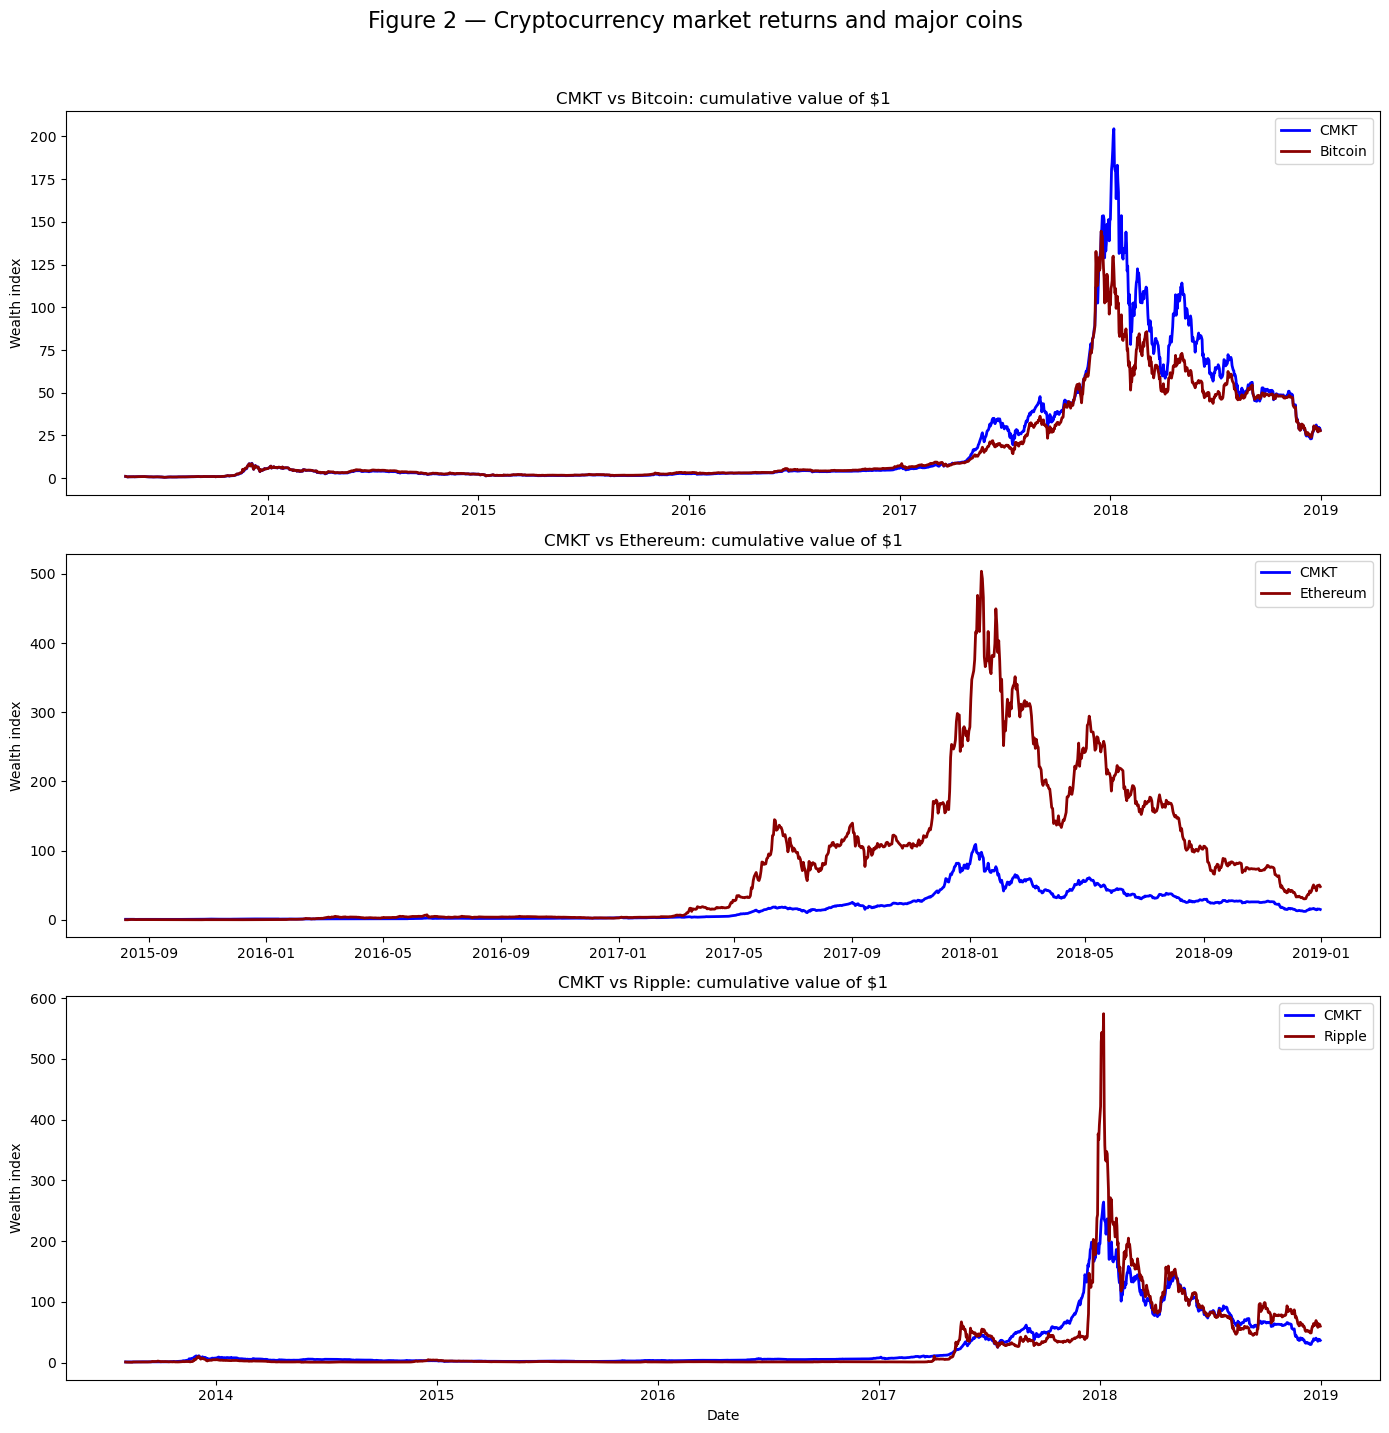

In [5]:
# Figure 2: Cryptocurrency Market Returns and Major Coins

def wealth_index(s: pd.Series) -> pd.Series:
    s = s.dropna().copy()
    return (1.0 + s).cumprod()

plot_df = daily[[
    "time", "CMKT", "bitcoin_full_return", "ethereum_return", "ripple_return"
]].copy()

series_info = [
    ("Bitcoin",  "bitcoin_full_return", pd.Timestamp("2013-04-29", tz="UTC")),
    ("Ethereum", "ethereum_return",     pd.Timestamp("2015-08-08", tz="UTC")),
    ("Ripple",   "ripple_return",       pd.Timestamp("2013-08-05", tz="UTC")),
]

# Same colors as the paper
cmkt_color = "blue"
coin_color = "darkred"

common_start = min(start_date for _, _, start_date in series_info)
common_end = pd.Timestamp(SAMPLE_END, tz="UTC")

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

for ax, (name, col, start_date) in zip(axes, series_info):
    tmp = plot_df.loc[plot_df["time"] >= start_date, ["time", "CMKT", col]].dropna().copy()

    tmp["CMKT_wealth"] = wealth_index(tmp["CMKT"]).values
    tmp[f"{name}_wealth"] = wealth_index(tmp[col]).values

    ax.plot(
        tmp["time"],
        tmp["CMKT_wealth"],
        label="CMKT",
        linewidth=2,
        color=cmkt_color
    )

    ax.plot(
        tmp["time"],
        tmp[f"{name}_wealth"],
        label=name,
        linewidth=2,
        color=coin_color
    )

    ax.set_title(f"CMKT vs {name}: cumulative value of $1")
    ax.set_ylabel("Wealth index")
    ax.set_xlim(common_start, common_end)
    ax.legend()

axes[-1].set_xlabel("Date")
plt.suptitle("Figure 2 — Cryptocurrency market returns and major coins", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
# Table 6: Time Series Momentum

import numpy as np
import pandas as pd


def hac_mean_tstat(series: pd.Series, lags: int):
    y = pd.Series(series).dropna().astype(float)
    if len(y) == 0:
        return np.nan, np.nan

    X = np.ones((len(y), 1))
    fit = sm.OLS(y.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(fit.params[0]), float(fit.tvalues[0])

def run_predictive_regression(y: pd.Series, x: pd.Series, lags: int):
    tmp = pd.DataFrame({"y": y, "x": x}).dropna().copy()
    X = sm.add_constant(tmp["x"])
    fit = sm.OLS(tmp["y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

    return {
        "N": int(fit.nobs),
        "coef": float(fit.params["x"]),
        "tstat": float(fit.tvalues["x"]),
        "R2": float(fit.rsquared),
    }


def significance_stars(t):
    at = abs(t)
    if at >= 2.58:
        return "***"
    elif at >= 1.96:
        return "**"
    elif at >= 1.645:
        return "*"
    return ""

def cumulative_future_return(r: pd.Series, h: int) -> pd.Series:
    r = pd.Series(r).reset_index(drop=True)
    out = pd.Series(np.nan, index=r.index, dtype="float64")

    vals = r.to_numpy()
    for i in range(len(vals)):
        future = vals[i+1:i+1+h]
        if len(future) == h and np.isfinite(future).all():
            out.iloc[i] = np.prod(1.0 + future) - 1.0

    return out

mom = weekly[["time", "CMKT"]].dropna().copy().reset_index(drop=True)


panel_a_horizons = [1, 2, 3, 4, 6, 8]
panel_a_cols = [
    "R$_{t,t+1}$\n(1)",
    "R$_{t,t+2}$\n(2)",
    "R$_{t,t+3}$\n(3)",
    "R$_{t,t+4}$\n(4)",
    "R$_{t,t+6}$\n(5)",
    "R$_{t,t+8}$\n(6)",
]

coef_row = {"Weekly": "R$_t$"}
r2_row = {"Weekly": "R$^2$"}

for h, col_label in zip(panel_a_horizons, panel_a_cols):
    tmp = mom.copy()
    tmp[f"future_{h}w"] = cumulative_future_return(tmp["CMKT"], h)

    reg = run_predictive_regression(
        y=tmp[f"future_{h}w"],
        x=tmp["CMKT"],
        lags=h-1
    )

    coef_row[col_label] = f"{reg['coef']:.2f}{significance_stars(reg['tstat'])}\n({reg['tstat']:.2f})"
    r2_row[col_label] = f"{reg['R2']:.2f}"

table6_panel_a = pd.DataFrame([coef_row, r2_row])

print("Table 6")
print("Time-series momentum")
print("\nPanel A. Regression results")
display(
    table6_panel_a.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "white-space": "pre-line"
    })
)

sort_df = mom.copy()
sort_df["rank"] = pd.qcut(
    sort_df["CMKT"],
    q=3,
    labels=["Low", "Middle", "High"],
    duplicates="drop"
)

for h in [1, 2, 4]:
    sort_df[f"future_{h}w"] = cumulative_future_return(sort_df["CMKT"], h)

panel_b_rows = []

for rank in ["Low", "Middle", "High"]:
    row = {"Rank": rank}

    row["R$_t$"] = f"{100 * sort_df.loc[sort_df['rank'] == rank, 'CMKT'].mean():.2f}"

    for h in [1, 2, 4]:
        mean_h, t_h = hac_mean_tstat(
            sort_df.loc[sort_df["rank"] == rank, f"future_{h}w"],
            lags=h-1
        )
        row[f"R$_{{t,t+{h}}}$"] = f"{100 * mean_h:.2f}"
        row[f"t-stat {h}"] = f"({t_h:.2f})"

    panel_b_rows.append(row)

diff_row = {"Rank": "Diff"}
diff_row["R$_t$"] = ""

for h in [1, 2, 4]:
    high_mean = sort_df.loc[sort_df["rank"] == "High", f"future_{h}w"].mean()
    low_mean  = sort_df.loc[sort_df["rank"] == "Low",  f"future_{h}w"].mean()
    diff_row[f"R$_{{t,t+{h}}}$"] = f"{100 * (high_mean - low_mean):.2f}"
    diff_row[f"t-stat {h}"] = ""

panel_b_rows.append(diff_row)

table6_panel_b = pd.DataFrame(panel_b_rows)[[
    "Rank", "R$_t$",
    "R$_{t,t+1}$", "t-stat 1",
    "R$_{t,t+2}$", "t-stat 2",
    "R$_{t,t+4}$", "t-stat 4"
]]

print("\nPanel B. Sorting results")
print("\nTime-series momentum by groups (weekly, percentage)")
display(
    table6_panel_b.style
    .hide(axis="index")
    .set_properties(**{"text-align": "center"})
)

oos_df = mom.copy()

cutoff_end = oos_df["time"].min() + pd.DateOffset(years=2)
train = oos_df.loc[oos_df["time"] < cutoff_end, "CMKT"].dropna()
test  = oos_df.loc[oos_df["time"] >= cutoff_end].copy().reset_index(drop=True)

q1, q2 = train.quantile([1/3, 2/3]).values

def assign_tercile(x):
    if x <= q1:
        return "Low"
    elif x <= q2:
        return "Middle"
    else:
        return "High"

test["rank"] = test["CMKT"].apply(assign_tercile)

for h in [1, 2, 4]:
    test[f"future_{h}w"] = cumulative_future_return(test["CMKT"], h)

oos_rows = []

for rank in ["Low", "Middle", "High"]:
    row = {"Rank": rank}

    row["R$_t$"] = f"{100 * test.loc[test['rank'] == rank, 'CMKT'].mean():.2f}"

    for h in [1, 2, 4]:
        mean_h, t_h = hac_mean_tstat(
            test.loc[test["rank"] == rank, f"future_{h}w"],
            lags=h-1
        )
        row[f"R$_{{t,t+{h}}}$"] = f"{100 * mean_h:.2f}"
        row[f"t-stat {h}"] = f"({t_h:.2f})"

    oos_rows.append(row)

diff_row = {"Rank": "Diff"}
diff_row["R$_t$"] = ""

for h in [1, 2, 4]:
    high_mean = test.loc[test["rank"] == "High", f"future_{h}w"].mean()
    low_mean  = test.loc[test["rank"] == "Low",  f"future_{h}w"].mean()
    diff_row[f"R$_{{t,t+{h}}}$"] = f"{100 * (high_mean - low_mean):.2f}"
    diff_row[f"t-stat {h}"] = ""

oos_rows.append(diff_row)

table6_panel_b_oos = pd.DataFrame(oos_rows)[[
    "Rank", "R$_t$",
    "R$_{t,t+1}$", "t-stat 1",
    "R$_{t,t+2}$", "t-stat 2",
    "R$_{t,t+4}$", "t-stat 4"
]]

print("\nTime-series momentum by groups—No lookahead (weekly, percentage)")
display(
    table6_panel_b_oos.style
    .hide(axis="index")
    .set_properties(**{"text-align": "center"})
)

Table 6
Time-series momentum

Panel A. Regression results


Weekly,"R$_{t,t+1}$ (1)","R$_{t,t+2}$ (2)","R$_{t,t+3}$ (3)","R$_{t,t+4}$ (4)","R$_{t,t+6}$ (5)","R$_{t,t+8}$ (6)"
R$_t$,0.20** (2.49),0.49*** (2.75),0.80*** (3.03),1.07*** (2.63),1.53* (1.93),1.56* (1.72)
R$^2$,0.04,0.08,0.09,0.08,0.05,0.02



Panel B. Sorting results

Time-series momentum by groups (weekly, percentage)


Rank,R$_t$,"R$_{t,t+1}$",t-stat 1,"R$_{t,t+2}$",t-stat 2,"R$_{t,t+4}$",t-stat 4
Low,-10.61,1.37,(1.14),3.85,(1.60),5.83,(1.13)
Middle,1.56,1.41,(1.54),4.28,(2.28),13.06,(3.12)
High,19.44,7.62,(4.13),14.73,(3.73),37.12,(3.17)
Diff,,6.25,,10.88,,31.29,



Time-series momentum by groups—No lookahead (weekly, percentage)


Rank,R$_t$,"R$_{t,t+1}$",t-stat 1,"R$_{t,t+2}$",t-stat 2,"R$_{t,t+4}$",t-stat 4
Low,-9.74,0.99,(0.86),2.60,(1.43),2.90,(1.00)
Middle,1.78,1.98,(1.86),3.82,(1.96),10.32,(2.37)
High,17.09,5.36,(3.01),11.24,(2.89),28.21,(2.50)
Diff,,4.38,,8.63,,25.31,


In [7]:
# Table 12: Valuation Ratios

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.decomposition import PCA


val = weekly.copy()
val = val.dropna(subset=["CMKT", "total_market_cap"]).copy().reset_index(drop=True)

def cumulative_future_return(r: pd.Series, h: int) -> pd.Series:
    r = pd.Series(r).reset_index(drop=True)
    out = pd.Series(np.nan, index=r.index, dtype="float64")

    vals = r.to_numpy()
    for i in range(len(vals)):
        future = vals[i+1:i+1+h]
        if len(future) == h and np.isfinite(future).all():
            out.iloc[i] = np.prod(1.0 + future) - 1.0

    return out

def run_predictive_regression(y: pd.Series, x: pd.Series, lags: int):
    tmp = pd.DataFrame({"y": y, "x": x}).dropna().copy()
    X = sm.add_constant(tmp["x"])
    fit = sm.OLS(tmp["y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

    return {
        "N": int(fit.nobs),
        "coef": float(fit.params["x"]),
        "tstat": float(fit.tvalues["x"]),
        "R2": float(fit.rsquared),
    }

def significance_stars(t):
    at = abs(t)
    if at >= 2.58:
        return "***"
    elif at >= 1.96:
        return "**"
    elif at >= 1.645:
        return "*"
    return ""

def cointegration_residual_ratio(fundamental: pd.Series, market_cap: pd.Series) -> pd.Series:
    tmp = pd.DataFrame({"fundamental": fundamental, "mcap": market_cap}).dropna().copy()
    tmp = tmp.loc[(tmp["fundamental"] > 0) & (tmp["mcap"] > 0)].copy()

    out = pd.Series(np.nan, index=fundamental.index, dtype="float64")
    if len(tmp) < 20:
        return out

    X = sm.add_constant(np.log(tmp["mcap"]))
    y = np.log(tmp["fundamental"])
    fit = sm.OLS(y, X).fit()

    out.loc[tmp.index] = fit.resid
    return out

val["Past100"] = -val["CMKT"].rolling(100).apply(
    lambda x: np.prod(1.0 + x) - 1.0,
    raw=True
)

val["Add_MCAP"] = np.nan
val["Trans_MCAP"] = np.nan
val["Pay_MCAP"] = np.nan

if "active_addresses" in val.columns:
    val["Add_MCAP"] = cointegration_residual_ratio(val["active_addresses"], val["total_market_cap"])

if "transaction_count" in val.columns:
    val["Trans_MCAP"] = cointegration_residual_ratio(val["transaction_count"], val["total_market_cap"])

if "payment_transfer_count" in val.columns:
    val["Pay_MCAP"] = cointegration_residual_ratio(val["payment_transfer_count"], val["total_market_cap"])


proxy_order = ["Past100", "Add_MCAP", "Trans_MCAP", "Pay_MCAP"]
available_proxies = [c for c in proxy_order if c in val.columns and val[c].notna().sum() > 0]

# The principal component
val["PC"] = np.nan
pca_input = val[available_proxies].dropna().copy()

if len(pca_input) >= 20:
    z = (pca_input - pca_input.mean()) / pca_input.std(ddof=0)
    pc1 = PCA(n_components=1).fit_transform(z)[:, 0]
    val.loc[pca_input.index, "PC"] = pc1

panel_a_cols = ["Past100", "Add_MCAP", "Trans_MCAP", "Pay_MCAP"]
if val["PC"].notna().sum() > 0:
    panel_a_cols_with_pc = panel_a_cols + ["PC"]
else:
    panel_a_cols_with_pc = panel_a_cols.copy()

corr = val[panel_a_cols_with_pc].corr()

display_name_map = {
    "Past100": "Past100",
    "Add_MCAP": "Add/MCAP",
    "Trans_MCAP": "Trans/MCAP",
    "Pay_MCAP": "Pay/MCAP",
    "PC": "PC",
}

panel_a_display = corr.copy()
panel_a_display.index = [display_name_map[c] for c in panel_a_display.index]
panel_a_display.columns = [display_name_map[c] for c in panel_a_display.columns]

for i in range(len(panel_a_display.index)):
    for j in range(len(panel_a_display.columns)):
        row_name = panel_a_display.index[i]
        if row_name != "PC" and j < i:
            panel_a_display.iloc[i, j] = np.nan

panel_a_display = panel_a_display.applymap(
    lambda x: "" if pd.isna(x) else f"{x:.2f}"
)

print("Table 12")
print("Cryptocurrency valuation ratio")
print("\nPanel A. Correlation of fundamental-to-market ratios")
display(
    panel_a_display.style
    .set_properties(**{"text-align": "center"})
)

panel_b_horizons = [1, 2, 3, 4, 6, 8]
panel_b_cols = [
    "R$_{t,t+1}$\n(1)",
    "R$_{t,t+2}$\n(2)",
    "R$_{t,t+3}$\n(3)",
    "R$_{t,t+4}$\n(4)",
    "R$_{t,t+6}$\n(5)",
    "R$_{t,t+8}$\n(6)",
]

predictors_for_panel_b = available_proxies.copy()
if val["PC"].notna().sum() > 0:
    predictors_for_panel_b.append("PC")

predictor_label_map = {
    "Past100": "Past100",
    "Add_MCAP": "Add/MCAP",
    "Trans_MCAP": "Trans/MCAP",
    "Pay_MCAP": "Pay/MCAP",
    "PC": "PC",
}

panel_b_rows = []

for predictor in predictors_for_panel_b:
    coef_row = {"": predictor_label_map[predictor]}
    r2_row = {"": "R$^2$"}

    for h, col_label in zip(panel_b_horizons, panel_b_cols):
        tmp = val[["time", "CMKT", predictor]].copy()
        tmp[f"future_{h}w"] = cumulative_future_return(tmp["CMKT"], h)

        reg = run_predictive_regression(
            y=tmp[f"future_{h}w"],
            x=tmp[predictor],
            lags=h-1
        )

        coef_row[col_label] = f"{reg['coef']:.2f}{significance_stars(reg['tstat'])}\n({reg['tstat']:.2f})"
        r2_row[col_label] = f"{reg['R2']:.2f}"

    panel_b_rows.append(coef_row)
    panel_b_rows.append(r2_row)

table12_panel_b = pd.DataFrame(panel_b_rows)

print("\nPanel B. Predictive regressions")
display(
    table12_panel_b.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "white-space": "pre-line"
    })
)

Table 12
Cryptocurrency valuation ratio

Panel A. Correlation of fundamental-to-market ratios


,Past100,Add/MCAP,Trans/MCAP,Pay/MCAP,PC
Past100,1.00,0.54,0.56,0.53,0.69
Add/MCAP,,1.00,0.88,0.96,0.96
Trans/MCAP,,,1.00,0.91,0.97
Pay/MCAP,,,,1.00,0.96
PC,0.69,0.96,0.97,0.96,1.00



Panel B. Predictive regressions


,"R$_{t,t+1}$ (1)","R$_{t,t+2}$ (2)","R$_{t,t+3}$ (3)","R$_{t,t+4}$ (4)","R$_{t,t+6}$ (5)","R$_{t,t+8}$ (6)"
Past100,0.00 (0.38),0.00 (0.52),0.00 (0.64),0.00 (0.84),0.00 (1.05),0.01 (1.20)
R$^2$,0.00,0.00,0.01,0.01,0.02,0.02
Add/MCAP,0.01 (0.71),0.01 (0.38),0.01 (0.11),-0.00 (-0.03),-0.03 (-0.16),-0.08 (-0.25)
R$^2$,0.00,0.00,0.00,0.00,0.00,0.00
Trans/MCAP,0.03 (1.55),0.05 (1.29),0.06 (0.90),0.08 (0.72),0.12 (0.77),0.16 (0.71)
R$^2$,0.01,0.01,0.01,0.01,0.01,0.01
Pay/MCAP,0.01 (0.37),0.01 (0.20),-0.00 (-0.02),-0.02 (-0.12),-0.03 (-0.15),-0.07 (-0.23)
R$^2$,0.00,0.00,0.00,0.00,0.00,0.00
PC,0.01** (2.13),0.02** (2.34),0.03** (2.35),0.04** (2.39),0.07** (2.58),0.09** (2.52)
R$^2$,0.03,0.04,0.06,0.06,0.08,0.08


In [8]:
DATA_PATH = globals().get("DATA_PATH", "Dataset/Dataset.csv")
TABLE11_FREQ = "W-SUN"
TABLE11_HORIZONS = [1, 2, 3, 4, 6, 8]

def compound_return(x):
    x = pd.Series(x, dtype="float64").dropna()
    if x.empty:
        return np.nan
    return np.prod(1.0 + x.to_numpy()) - 1.0

def cumulative_future_return(r, h):
    r = pd.Series(r, dtype="float64").reset_index(drop=True)
    out = pd.Series(np.nan, index=r.index, dtype="float64")
    vals = r.to_numpy()
    for i in range(len(vals)):
        future = vals[i + 1:i + 1 + h]
        if len(future) == h and np.isfinite(future).all():
            out.iloc[i] = np.prod(1.0 + future) - 1.0
    return out

def significance_stars(t):
    at = abs(t)
    if at >= 2.58:
        return "***"
    if at >= 1.96:
        return "**"
    if at >= 1.645:
        return "*"
    return ""

def load_table11_panel(sample_start, sample_end):
    raw = pd.read_csv(DATA_PATH)
    raw["time"] = pd.to_datetime(raw["time"], utc=True, errors="coerce")
    raw = raw.dropna(subset=["time"]).sort_values("time").reset_index(drop=True)

    needed = {"CMKT", "bitcoin_search"}
    missing = needed.difference(raw.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    start = pd.Timestamp(sample_start, tz="UTC")
    end = pd.Timestamp(sample_end, tz="UTC") + pd.Timedelta(days=1)
    raw = raw.loc[(raw["time"] >= start) & (raw["time"] < end)].copy()

    weekly = (
        raw.set_index("time")
           .resample(TABLE11_FREQ)
           .agg({"CMKT": compound_return, "bitcoin_search": "last"})
           .dropna(subset=["CMKT", "bitcoin_search"])
           .reset_index()
    )

    weekly["Google_raw"] = weekly["bitcoin_search"] - weekly["bitcoin_search"].rolling(4).mean().shift(1)
    weekly = weekly.dropna(subset=["Google_raw"]).reset_index(drop=True)

    google_mean = weekly["Google_raw"].mean()
    google_std = weekly["Google_raw"].std(ddof=0)
    if not np.isfinite(google_std) or google_std == 0:
        raise ValueError("Google search measure has zero or invalid standard deviation.")

    weekly["Google"] = (weekly["Google_raw"] - google_mean) / google_std
    weekly["I_Google_gt_0"] = (weekly["Google"] > weekly["Google"].mean()).astype(int)
    weekly["I_R_gt_0"] = (weekly["CMKT"] > 0).astype(int)
    weekly["CMKT_x_I_Google_gt_0"] = weekly["CMKT"] * weekly["I_Google_gt_0"]
    weekly["Google_x_I_R_gt_0"] = weekly["Google"] * weekly["I_R_gt_0"]

    return weekly

def fit_hac(y, X, lags):
    sample = pd.concat([pd.Series(y, name="y"), X], axis=1).dropna().copy()
    X_fit = sm.add_constant(sample.drop(columns="y"), has_constant="add")
    return sm.OLS(sample["y"], X_fit).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

def build_table11(panel):
    col_labels = [
        "R$_{t,t+1}$ (1)",
        "R$_{t,t+2}$ (2)",
        "R$_{t,t+3}$ (3)",
        "R$_{t,t+4}$ (4)",
        "R$_{t,t+6}$ (5)",
        "R$_{t,t+8}$ (6)",
    ]

    row_blocks = [
        [("R$_t$", "CMKT"), ("Google$_t$", "Google"), ("R$^2$", None)],
        [("R$_t$", "CMKT"), ("1{Google>0}", "I_Google_gt_0"), ("R$_t$ × 1{Google>0}", "CMKT_x_I_Google_gt_0"), ("R$^2$", None)],
        [("Google$_t$", "Google"), ("1{R>0}", "I_R_gt_0"), ("Google$_t$ × 1{R>0}", "Google_x_I_R_gt_0"), ("R$^2$", None)],
    ]

    reg_specs = [
        ["CMKT", "Google"],
        ["CMKT", "I_Google_gt_0", "CMKT_x_I_Google_gt_0"],
        ["Google", "I_R_gt_0", "Google_x_I_R_gt_0"],
    ]

    out = pd.DataFrame({"Weekly": [label for block in row_blocks for label, _ in block]})

    for h, col in zip(TABLE11_HORIZONS, col_labels):
        tmp = panel.copy()
        tmp["future_return"] = cumulative_future_return(tmp["CMKT"], h)

        cells = []
        for reg_cols, block in zip(reg_specs, row_blocks):
            fit = fit_hac(tmp["future_return"], tmp[reg_cols], lags=h - 1)
            for _, var in block:
                if var is None:
                    cells.append(f"{fit.rsquared:.2f}")
                else:
                    coef = float(fit.params[var])
                    tval = float(fit.tvalues[var])
                    cells.append(f"{coef:.2f}{significance_stars(tval)}\n({tval:.2f})")
        out[col] = cells

    return out

def show_table11(table, panel, title):
    print(title)
    print(f"Weekly observations used: {len(panel)}")
    print(f"Weekly sample: {panel['time'].min().date()} to {panel['time'].max().date()}")
    display(
        table.style
        .hide(axis="index")
        .set_properties(**{"text-align": "center", "white-space": "pre-line"})
    )

table11_paper_window_panel = load_table11_panel("2011-01-01", "2018-12-31")
table11_paper_window = build_table11(table11_paper_window_panel)
show_table11(
    table11_paper_window,
    table11_paper_window_panel,
    "Table 11"
)

Table 11
Weekly observations used: 415
Weekly sample: 2011-01-30 to 2019-01-06


Weekly,"R$_{t,t+1}$ (1)","R$_{t,t+2}$ (2)","R$_{t,t+3}$ (3)","R$_{t,t+4}$ (4)","R$_{t,t+6}$ (5)","R$_{t,t+8}$ (6)"
R$_t$,0.17** (2.16),0.43** (2.39),0.70*** (2.60),0.95** (2.22),1.42* (1.71),1.45 (1.50)
Google$_t$,0.03*** (3.64),0.06*** (4.12),0.08*** (3.14),0.11*** (3.20),0.11** (2.22),0.11* (1.75)
R$^2$,0.07,0.13,0.12,0.11,0.06,0.02
R$_t$,0.23** (2.28),0.50** (2.09),0.85** (2.28),1.20* (1.95),2.02 (1.64),2.23 (1.49)
1{Google>0},0.05*** (2.61),0.10*** (2.77),0.16** (2.24),0.22** (2.04),0.34 (1.60),0.41 (1.29)
R$_t$ × 1{Google>0},-0.13 (-0.77),-0.15 (-0.40),-0.39 (-0.77),-0.66 (-0.91),-1.69 (-1.30),-2.31 (-1.43)
R$^2$,0.06,0.10,0.11,0.10,0.08,0.03
Google$_t$,0.03*** (2.84),0.06*** (2.76),0.09*** (4.08),0.09** (2.53),0.14** (2.40),0.28*** (2.59)
1{R>0},0.04*** (2.77),0.06** (2.31),0.12*** (2.84),0.17*** (2.65),0.22* (1.90),0.10 (0.58)
Google$_t$ × 1{R>0},0.00 (0.16),0.01 (0.39),0.01 (0.25),0.05 (0.82),-0.01 (-0.09),-0.18 (-1.44)
